# Parte Comum — EDA do dataset Obesity

Análise exploratória nos quatro pilares: estrutural, distribucional, relacional e outliers.

Fonte: *Estimation of Obesity Levels Based on Eating Habits and Physical Condition*, UCI Machine Learning Repository (dataset 544).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ARQ_DADOS = Path('../../data/parte_comum/obesity.csv')
DIR_FIGURAS = Path('../../out/parte_comum/figuras')
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def salvar(fig, nome):
    fig.savefig(DIR_FIGURAS / f'{nome}.png', dpi=150, bbox_inches='tight')

## 1. Carga e visão estrutural

In [2]:
df = pd.read_csv(ARQ_DADOS)
print(f'{df.shape[0]} linhas x {df.shape[1]} colunas')
df.head()

2111 linhas x 17 colunas


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF                             2111 non-null

In [4]:
COL_CLASSE = 'NObeyesdad'

ORDEM_CLASSES = [
    'Insufficient_Weight',
    'Normal_Weight',
    'Overweight_Level_I',
    'Overweight_Level_II',
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III',
]

COLS_NUMERICAS = df.select_dtypes(include='number').columns.tolist()
COLS_CATEGORICAS = [c for c in df.select_dtypes(exclude='number').columns if c != COL_CLASSE]

print('Numéricas:', COLS_NUMERICAS)
print('Categóricas:', COLS_CATEGORICAS)
print('Classe:', COL_CLASSE, '-', df[COL_CLASSE].nunique(), 'classes')

Numéricas: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Categóricas: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']
Classe: NObeyesdad - 7 classes


### Dados faltantes e duplicatas

In [5]:
pd.DataFrame({
    'ausentes': df.isna().sum(),
    'pct_ausentes': df.isna().mean().mul(100).round(2),
})

,ausentes,pct_ausentes
Gender,0,0.0
Age,0,0.0
Height,0,0.0
Weight,0,0.0
family_history_with_overweight,0,0.0
FAVC,0,0.0
FCVC,0,0.0
NCP,0,0.0
CAEC,0,0.0
SMOKE,0,0.0


In [6]:
n_dup = df.duplicated().sum()
print(f'Linhas duplicadas: {n_dup}')
df[df.duplicated(keep=False)].sort_values(df.columns.tolist())

Linhas duplicadas: 24


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
295,Female,16.0,1.66,58.0,no,no,2.0,1.0,Sometimes,no,1.0,no,0.0,1.0,no,Walking,Normal_Weight
309,Female,16.0,1.66,58.0,no,no,2.0,1.0,Sometimes,no,1.0,no,0.0,1.0,no,Walking,Normal_Weight
282,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
460,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
97,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
98,Female,21.0,1.52,42.0,no,no,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
523,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
527,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
659,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight
663,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight


### Cardinalidade das variáveis categóricas

In [7]:
df[COLS_CATEGORICAS + [COL_CLASSE]].nunique().to_frame('n_categorias')

,n_categorias
Gender,2
family_history_with_overweight,2
FAVC,2
CAEC,4
SMOKE,2
SCC,2
CALC,4
MTRANS,5
NObeyesdad,7


In [8]:
for col in COLS_CATEGORICAS + [COL_CLASSE]:
    print(f'--- {col}')
    print(df[col].value_counts().to_string(), end='\n\n')

--- Gender


Gender
Male      1068
Female    1043

--- family_history_with_overweight
family_history_with_overweight
yes    1726
no      385

--- FAVC
FAVC
yes    1866
no      245

--- CAEC
CAEC
Sometimes     1765
Frequently     242
Always          53
no              51

--- SMOKE
SMOKE
no     2067
yes      44

--- SCC
SCC
no     2015
yes      96

--- CALC
CALC
Sometimes     1401
no             639
Frequently      70
Always           1

--- MTRANS
MTRANS
Public_Transportation    1580
Automobile                457
Walking                    56
Motorbike                  11
Bike                        7

--- NObeyesdad
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272



### Variáveis numéricas em escala

`FCVC`, `NCP`, `CH2O`, `FAF` e `TUE` são respostas de questionário em escala, mas aparecem como decimais.
A tabela mostra o percentual de valores não inteiros em cada uma.

In [9]:
COLS_ESCALA = ['FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

pd.DataFrame({
    'min': df[COLS_ESCALA].min(),
    'max': df[COLS_ESCALA].max(),
    'pct_nao_inteiros': (df[COLS_ESCALA] % 1 != 0).mean().mul(100).round(1),
})

,min,max,pct_nao_inteiros
FCVC,1.0,3.0,39.1
NCP,1.0,4.0,30.3
CH2O,1.0,3.0,61.1
FAF,0.0,3.0,57.2
TUE,0.0,2.0,54.6


**Análise do grupo:**

O dataset possui 2.111 registros e 17 colunas. Das 16 variáveis explicativas, oito estão armazenadas como numéricas e oito como categóricas. A coluna `NObeyesdad` reúne sete classes, de peso insuficiente a obesidade tipo III. Não há valores ausentes. A contagem de duplicatas indica 24 repetições além das primeiras ocorrências.

O tipo armazenado nem sempre corresponde à natureza da variável. `FCVC`, `NCP`, `CH2O`, `FAF` e `TUE` correspondem a respostas em escalas limitadas e contêm valores fracionários. Aproximadamente 77% da base foi gerada sinteticamente com SMOTE e 23% foi coletada diretamente por plataforma web, segundo a UCI. Essa composição ajuda a contextualizar os valores fracionários e limita o uso da amostra para inferir características da população. [Descrição oficial do dataset](https://doi.org/10.24432/C5H31Z)

## 2. Distribuições

### Estatísticas descritivas

In [10]:
desc = df[COLS_NUMERICAS].describe().T
desc['assimetria'] = df[COLS_NUMERICAS].skew()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,assimetria
Age,2111.0,24.313,6.346,14.00,19.947,22.778,26.000,61.00,1.529
Height,2111.0,1.702,0.093,1.45,1.630,1.700,1.768,1.98,-0.013
Weight,2111.0,86.586,26.191,39.00,65.473,83.000,107.431,173.00,0.255
FCVC,2111.0,2.419,0.534,1.00,2.000,2.386,3.000,3.00,-0.433
NCP,2111.0,2.686,0.778,1.00,2.659,3.000,3.000,4.00,-1.107
CH2O,2111.0,2.008,0.613,1.00,1.585,2.000,2.477,3.00,-0.105
FAF,2111.0,1.010,0.851,0.00,0.125,1.000,1.667,3.00,0.498
TUE,2111.0,0.658,0.609,0.00,0.000,0.625,1.000,2.00,0.619


### Variáveis numéricas

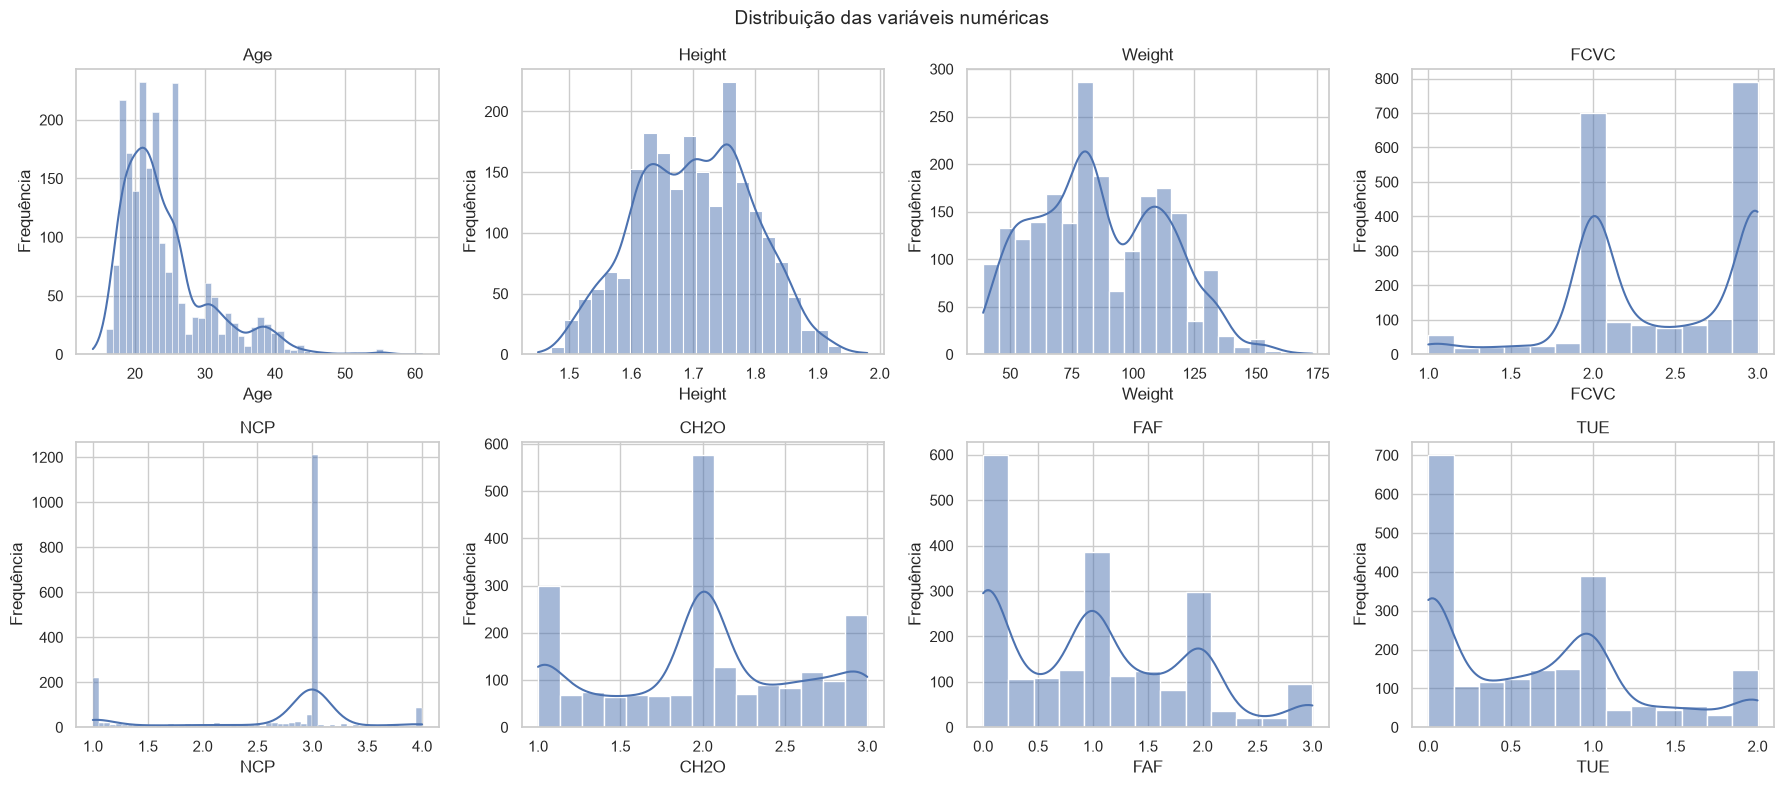

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, COLS_NUMERICAS):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Frequência')
fig.suptitle('Distribuição das variáveis numéricas', fontsize=14)
fig.tight_layout()
salvar(fig, 'eda_hist_numericas')
plt.show()

### Variáveis categóricas

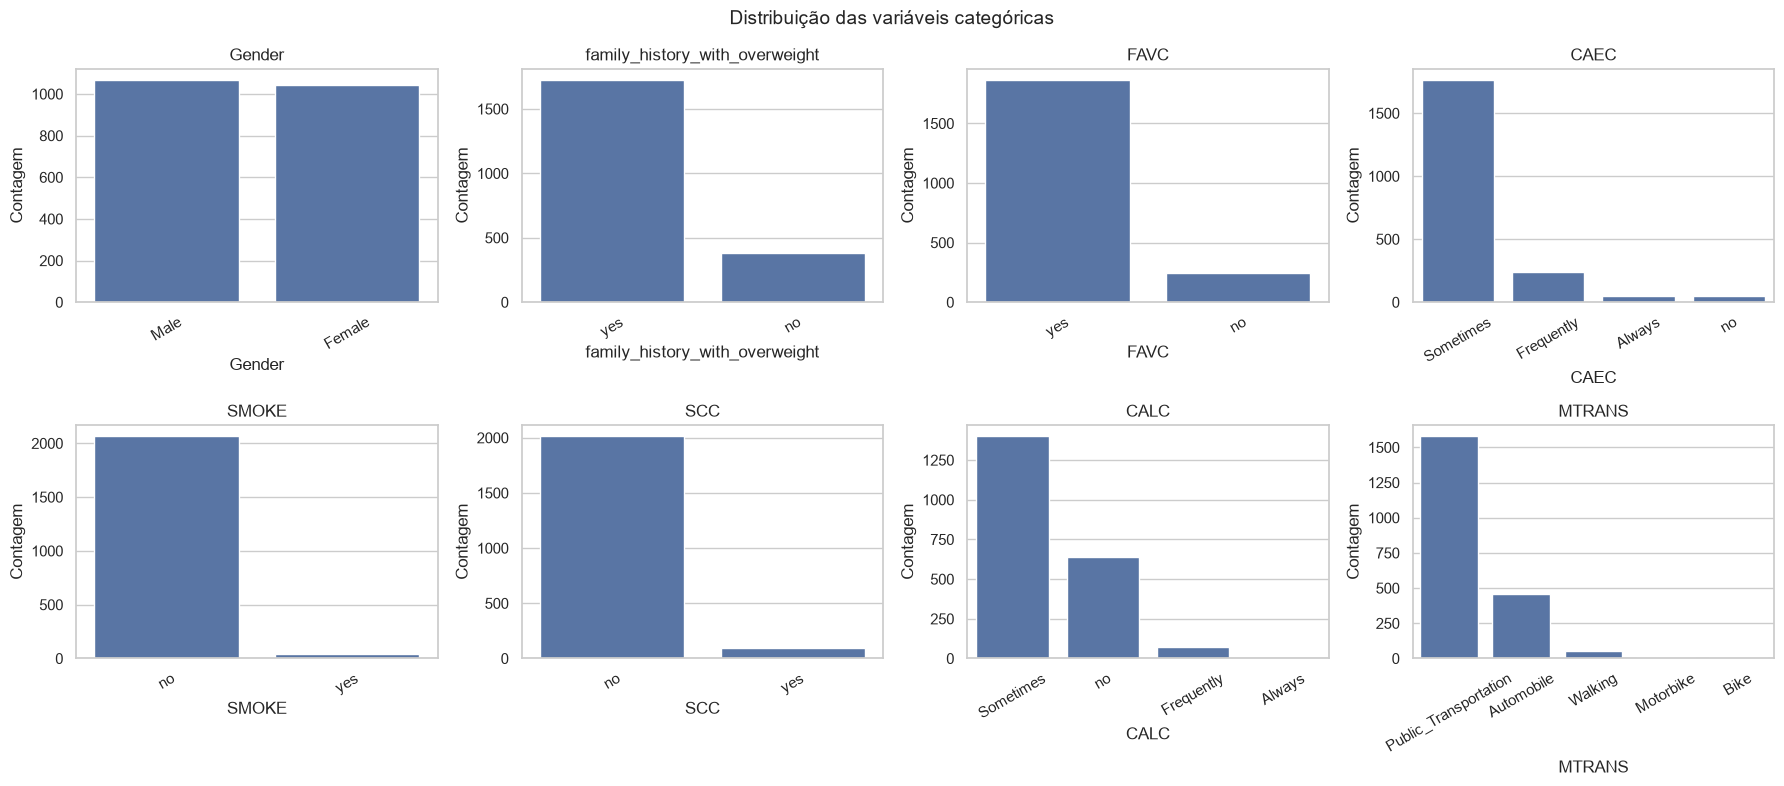

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, COLS_CATEGORICAS):
    ordem = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=ordem, ax=ax)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Contagem')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Distribuição das variáveis categóricas', fontsize=14)
fig.tight_layout()
salvar(fig, 'eda_contagem_categoricas')
plt.show()

### Variável de classe

In [13]:
contagem = df[COL_CLASSE].value_counts().reindex(ORDEM_CLASSES)
pd.DataFrame({'n': contagem, 'pct': (contagem / len(df) * 100).round(1)})

,n,pct
NObeyesdad,,
Insufficient_Weight,272,12.9
Normal_Weight,287,13.6
Overweight_Level_I,290,13.7
Overweight_Level_II,290,13.7
Obesity_Type_I,351,16.6
Obesity_Type_II,297,14.1
Obesity_Type_III,324,15.3


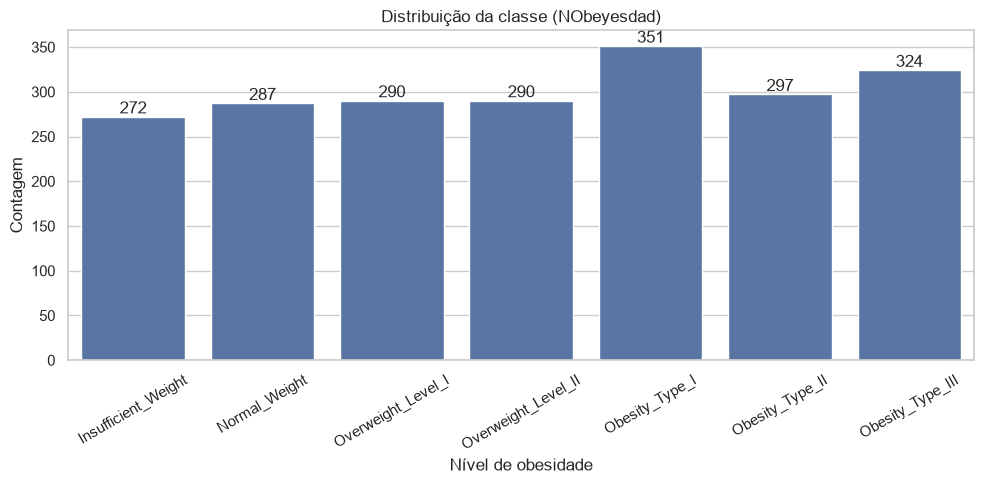

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df, x=COL_CLASSE, order=ORDEM_CLASSES, ax=ax)
ax.bar_label(ax.containers[0])
ax.set_title('Distribuição da classe (NObeyesdad)')
ax.set_xlabel('Nível de obesidade')
ax.set_ylabel('Contagem')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
salvar(fig, 'eda_classe')
plt.show()

**Análise do grupo:**

A idade tem média de 24,3 anos, mediana de 22,8 e assimetria à direita, com valores entre 14 e 61 anos. A altura é aproximadamente simétrica e tem média de 1,70 m. O peso varia de 39 a 173 kg, com mediana de 83 kg.

Nas escalas do questionário, `FCVC` se concentra próximo dos níveis 2 e 3. `NCP` se concentra em torno de três refeições principais e `CH2O` tem mediana 2. `FAF` tem mediana 1 e `TUE` se concentra na parte inferior da escala.

Entre as variáveis categóricas, predominam a resposta positiva para consumo frequente de alimentos calóricos (1.866 registros), a ausência de tabagismo (2.067) e o transporte público (1.580). Bicicleta e motocicleta têm apenas 7 e 11 registros, respectivamente. Percentuais dessas categorias devem ser lidos junto com suas contagens. As sete classes representam entre 12,9% e 16,6% da base. Essas proporções descrevem a amostra, que inclui registros sintéticos.

## 3. Relações entre variáveis, incluindo a classe

### Numérica × numérica

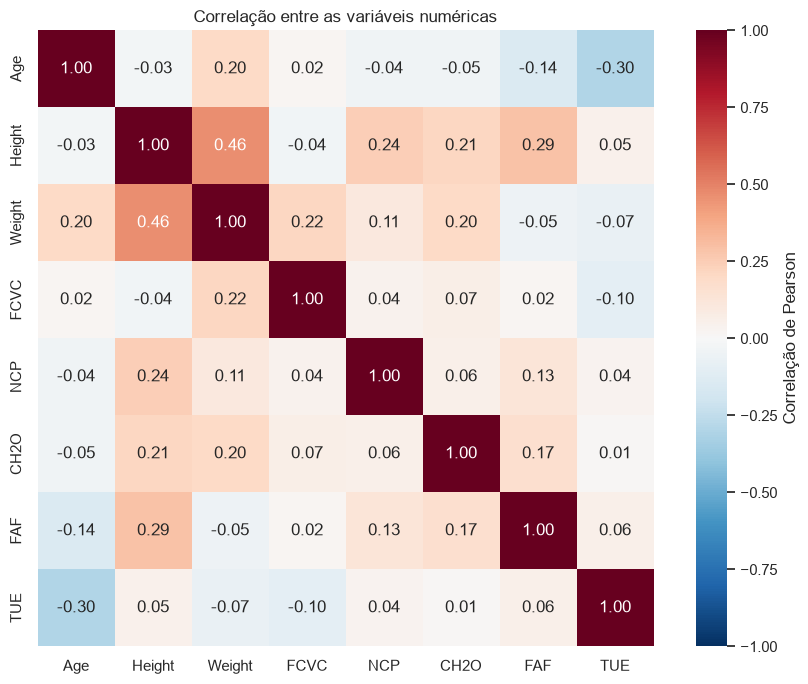

In [15]:
corr = df[COLS_NUMERICAS].corr(method='pearson')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'label': 'Correlação de Pearson'})
ax.set_title('Correlação entre as variáveis numéricas')
fig.tight_layout()
salvar(fig, 'eda_correlacao')
plt.show()

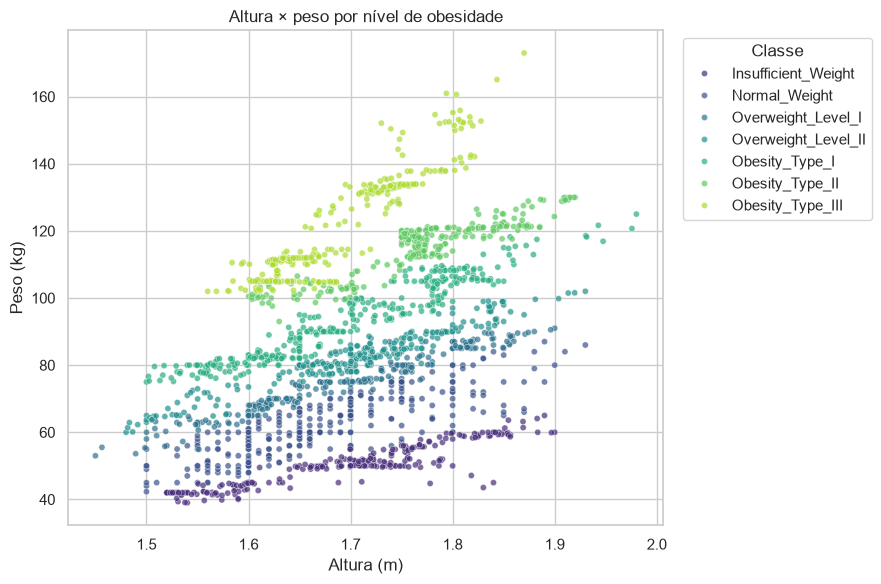

In [16]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x='Height', y='Weight', hue=COL_CLASSE, hue_order=ORDEM_CLASSES,
                palette='viridis', s=20, alpha=0.7, ax=ax)
ax.set_title('Altura × peso por nível de obesidade')
ax.set_xlabel('Altura (m)')
ax.set_ylabel('Peso (kg)')
ax.legend(title='Classe', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
salvar(fig, 'eda_altura_peso')
plt.show()

### Numérica × classe

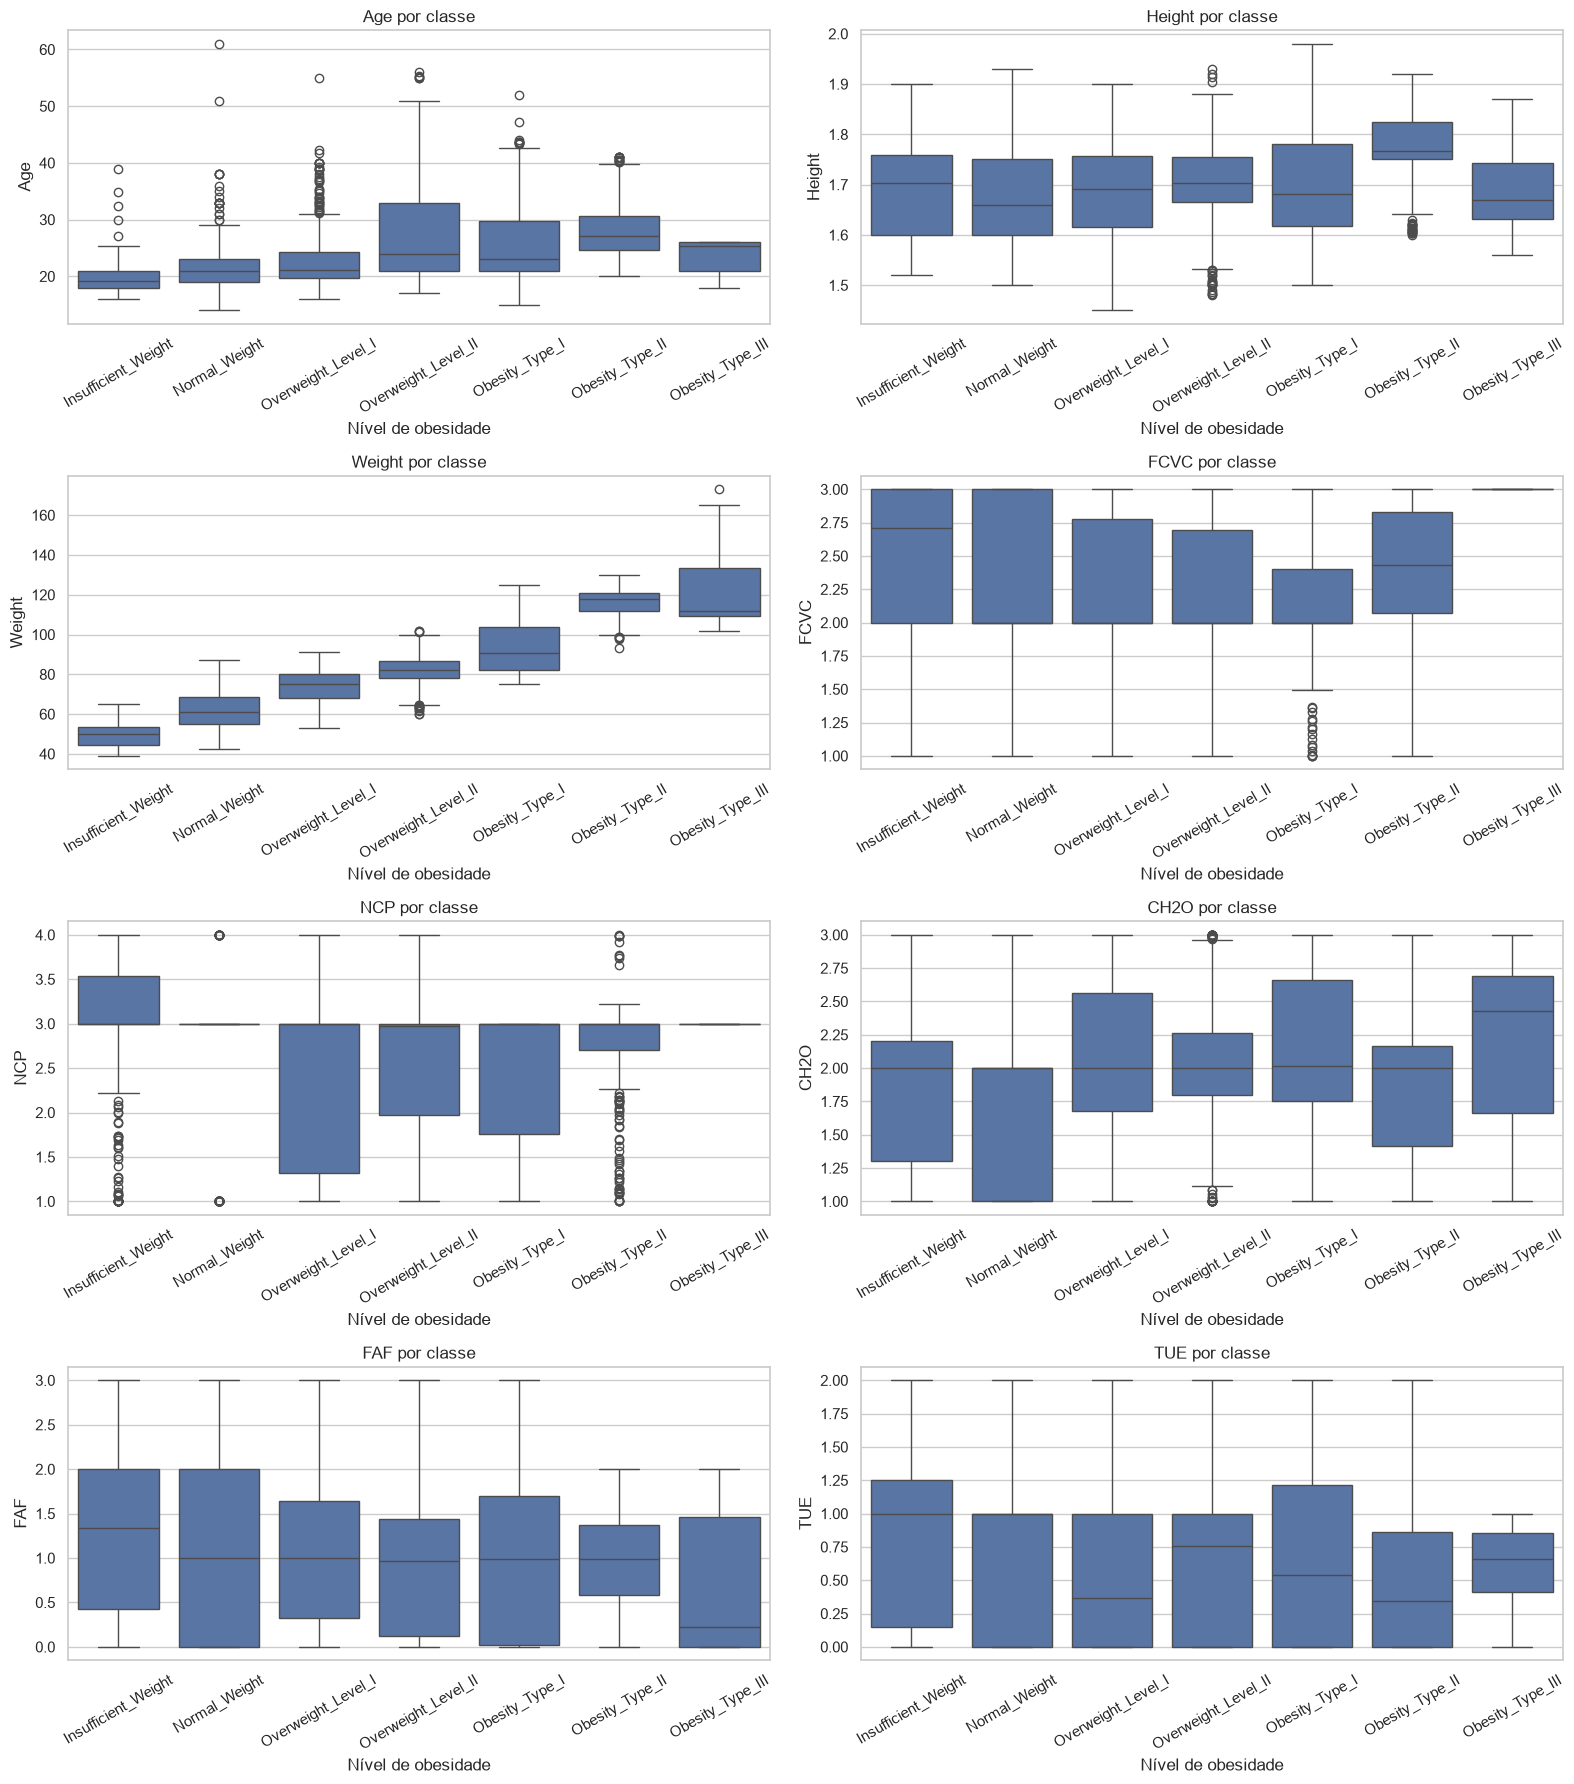

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
for ax, col in zip(axes.flat, COLS_NUMERICAS):
    sns.boxplot(data=df, x=COL_CLASSE, y=col, order=ORDEM_CLASSES, ax=ax)
    ax.set_title(f'{col} por classe')
    ax.set_xlabel('Nível de obesidade')
    ax.set_ylabel(col)
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
salvar(fig, 'eda_numericas_por_classe')
plt.show()

In [18]:
df.groupby(COL_CLASSE)[COLS_NUMERICAS].median().reindex(ORDEM_CLASSES).round(2)

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
NObeyesdad,,,,,,,,
Insufficient_Weight,19.24,1.70,50.00,2.71,3.00,2.00,1.34,1.00
Normal_Weight,21.00,1.66,61.00,2.00,3.00,2.00,1.00,1.00
Overweight_Level_I,21.05,1.69,75.00,2.00,3.00,2.00,1.00,0.36
Overweight_Level_II,24.00,1.70,82.00,2.00,2.98,2.00,0.96,0.75
Obesity_Type_I,22.98,1.68,90.74,2.00,3.00,2.01,0.99,0.54
Obesity_Type_II,27.19,1.77,117.79,2.43,3.00,2.00,0.99,0.34
Obesity_Type_III,25.37,1.67,112.05,3.00,3.00,2.43,0.22,0.66


### Categórica × classe

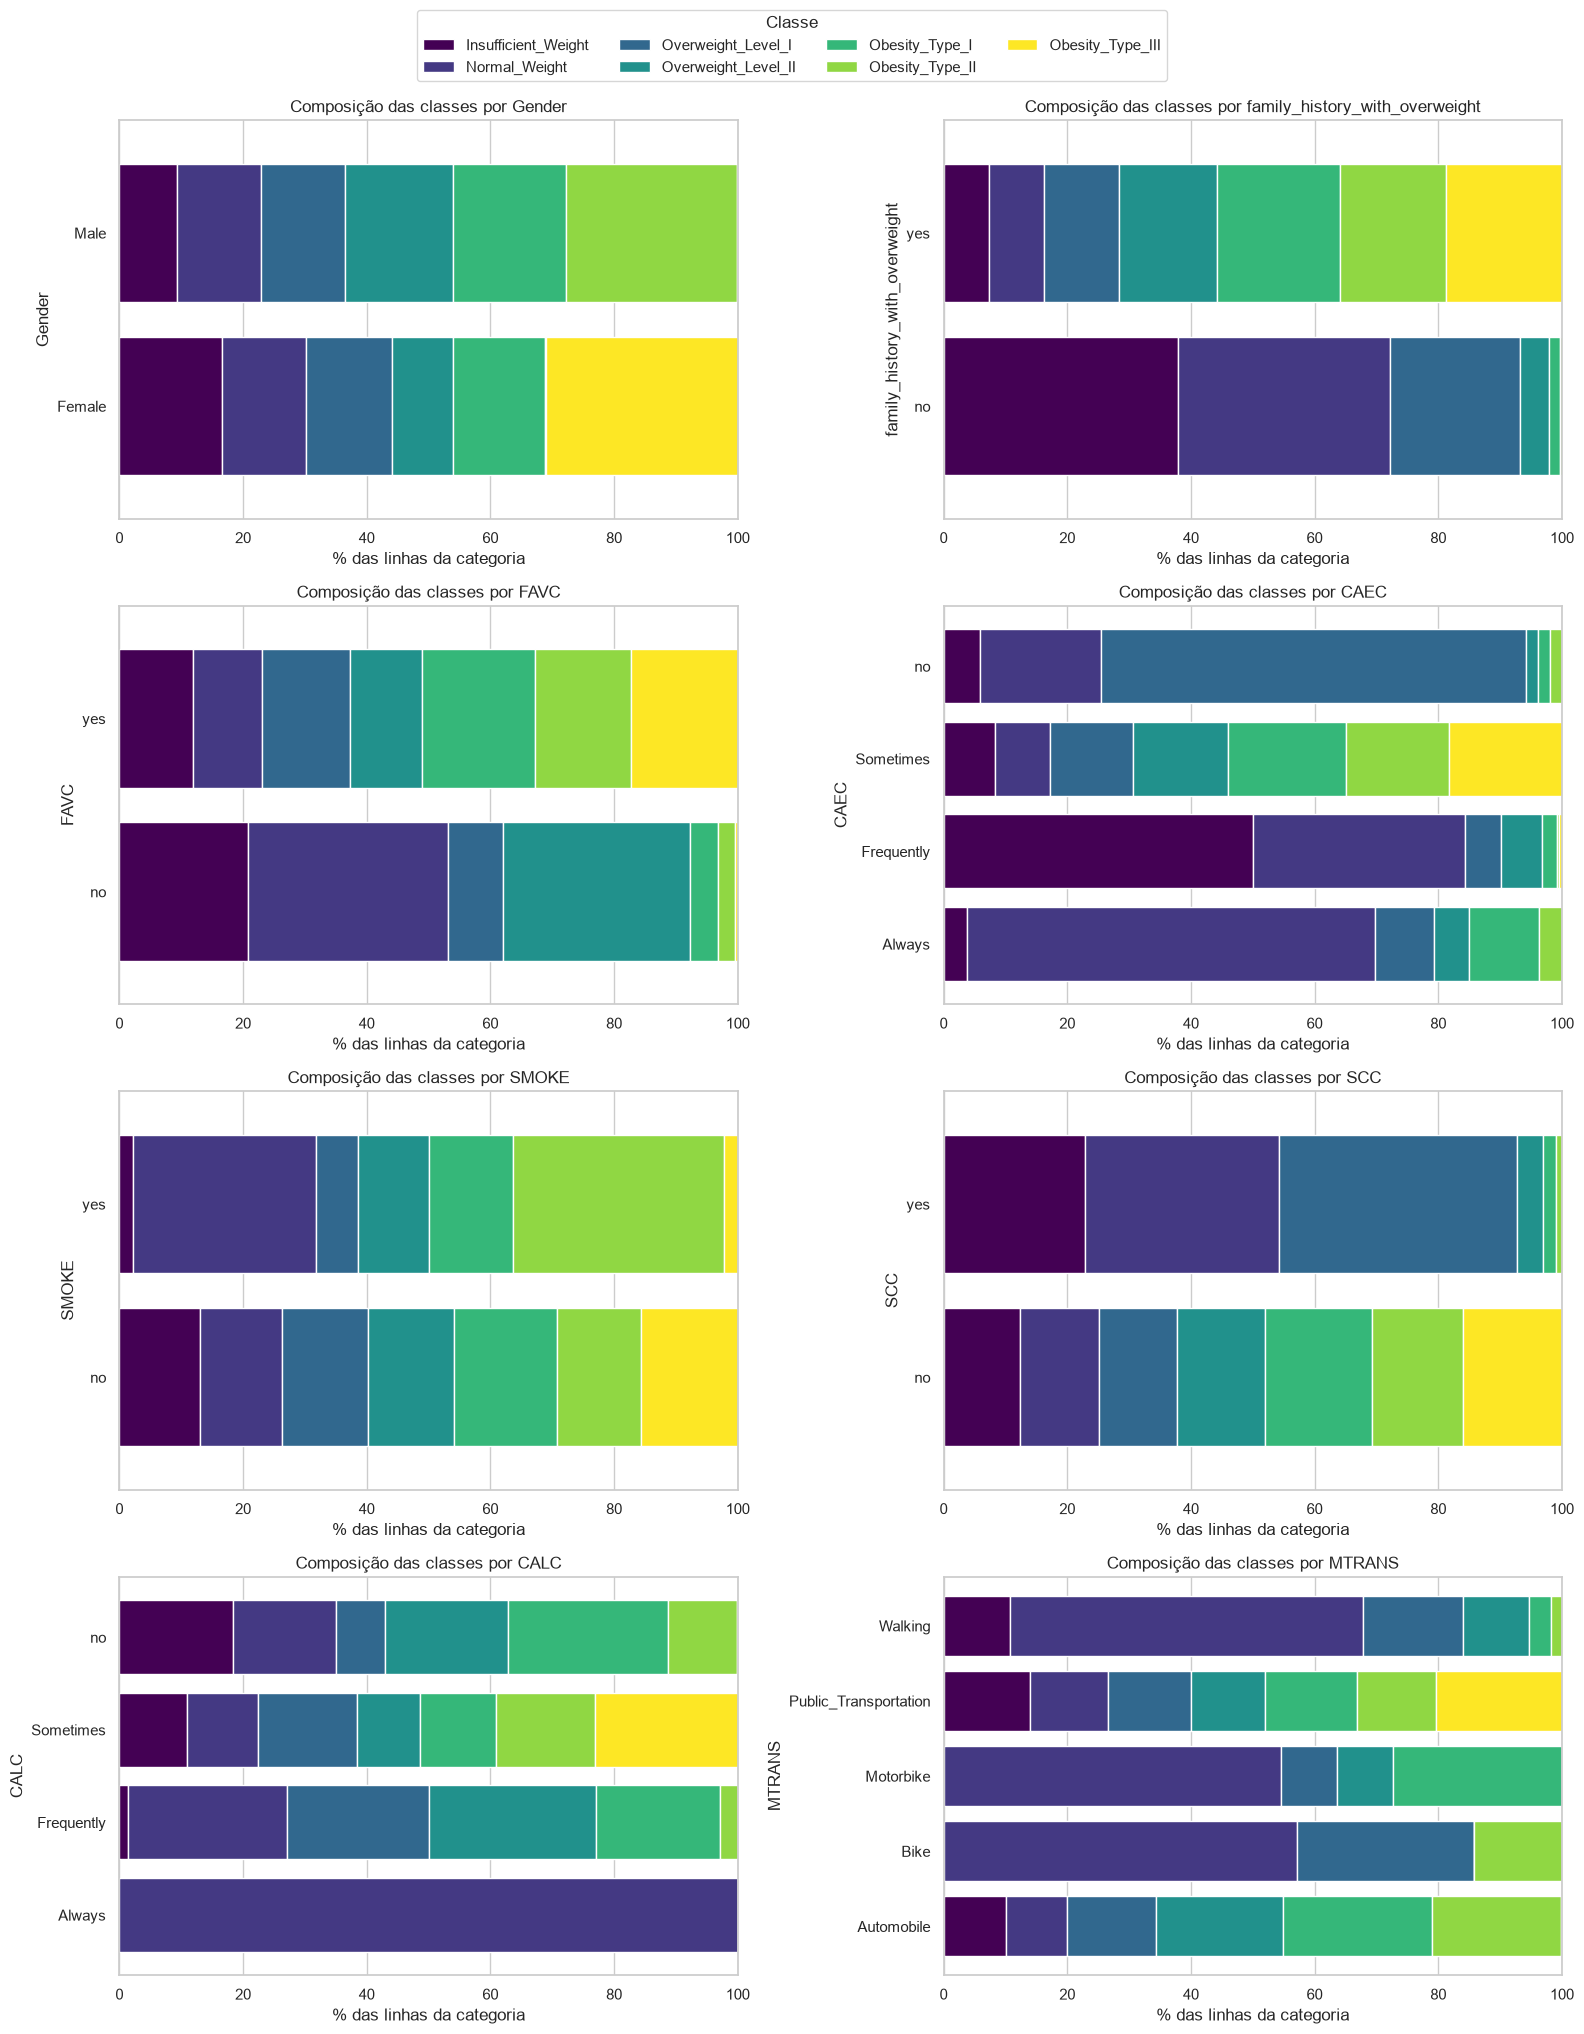

In [19]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for ax, col in zip(axes.flat, COLS_CATEGORICAS):
    tabela = pd.crosstab(df[col], df[COL_CLASSE], normalize='index')[ORDEM_CLASSES] * 100
    tabela.plot(kind='barh', stacked=True, colormap='viridis', ax=ax, legend=False, width=0.8)
    ax.set_title(f'Composição das classes por {col}')
    ax.set_xlabel('% das linhas da categoria')
    ax.set_ylabel(col)
    ax.set_xlim(0, 100)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Classe', loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.98))
salvar(fig, 'eda_categoricas_por_classe')
plt.show()

### Categórica × categórica (V de Cramér)

O V de Cramér mede a força da associação entre duas variáveis categóricas, de 0 (nenhuma) a 1 (total).
O qui-quadrado é calculado com numpy, porque o scipy não está na lista de bibliotecas permitidas.

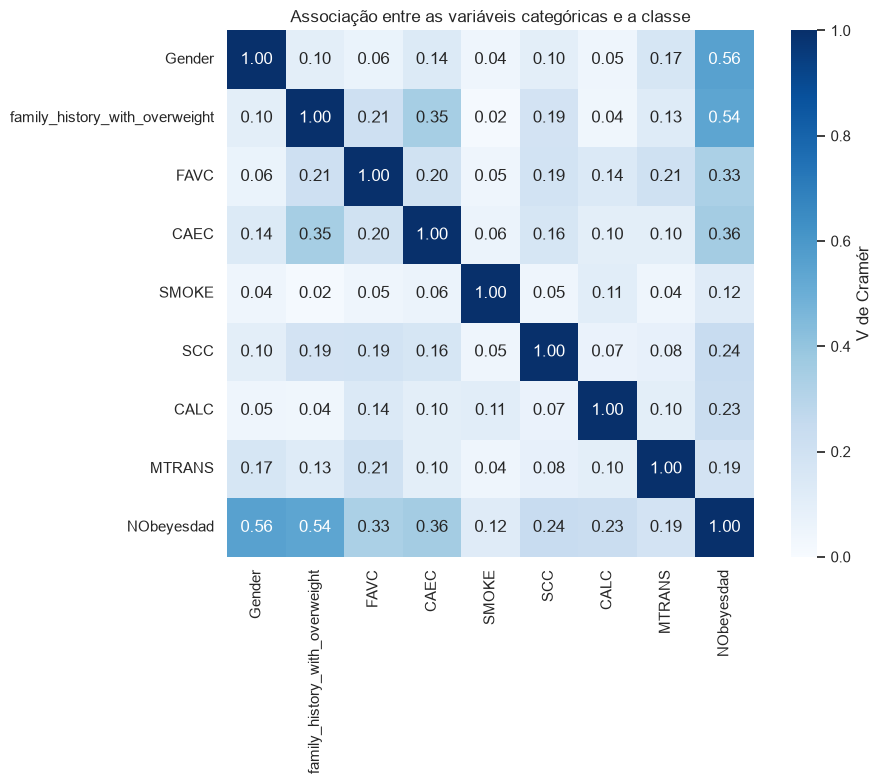

In [20]:
def cramers_v(x, y):
    tabela = pd.crosstab(x, y).to_numpy()
    n = tabela.sum()
    esperado = tabela.sum(axis=1, keepdims=True) @ tabela.sum(axis=0, keepdims=True) / n
    chi2 = ((tabela - esperado) ** 2 / esperado).sum()
    r, k = tabela.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


cols_assoc = COLS_CATEGORICAS + [COL_CLASSE]
matriz_v = pd.DataFrame(
    [[cramers_v(df[a], df[b]) for b in cols_assoc] for a in cols_assoc],
    index=cols_assoc, columns=cols_assoc,
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matriz_v, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True, ax=ax,
            cbar_kws={'label': 'V de Cramér'})
ax.set_title('Associação entre as variáveis categóricas e a classe')
fig.tight_layout()
salvar(fig, 'eda_cramers_v')
plt.show()

### Numérica × categórica (razão de correlação η)

A razão de correlação η mede quanto da variação de uma variável numérica é explicada pelas categorias
de uma variável categórica, de 0 (nenhuma) a 1 (total). A tabela cobre todos os pares entre as numéricas
e as categóricas explicativas, com a classe na última coluna para referência.

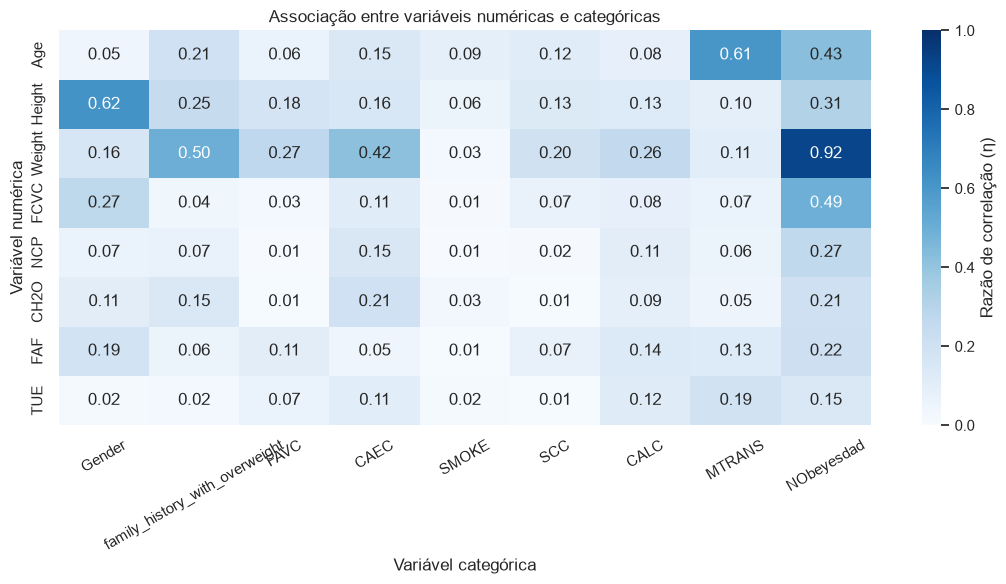

In [21]:
def razao_correlacao(categorias, valores):
    grupos = valores.groupby(categorias)
    media = valores.mean()
    ss_entre = (grupos.count() * (grupos.mean() - media) ** 2).sum()
    ss_total = ((valores - media) ** 2).sum()
    return np.sqrt(ss_entre / ss_total)


cols_cat_eta = COLS_CATEGORICAS + [COL_CLASSE]
matriz_eta = pd.DataFrame(
    [[razao_correlacao(df[cat], df[num]) for cat in cols_cat_eta] for num in COLS_NUMERICAS],
    index=COLS_NUMERICAS, columns=cols_cat_eta,
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(matriz_eta, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'Razão de correlação (η)'})
ax.set_title('Associação entre variáveis numéricas e categóricas')
ax.set_xlabel('Variável categórica')
ax.set_ylabel('Variável numérica')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
salvar(fig, 'eda_razao_correlacao')
plt.show()

Os boxplots abaixo mostram os pares entre numéricas e categóricas explicativas com maior η
(a classe fica de fora, pois já aparece na seção *Numérica × classe*). `N_PARES` controla quantos pares são exibidos.

eta
Height Gender                          0.618
Age    MTRANS                          0.607
Weight family_history_with_overweight  0.497
       CAEC                            0.419

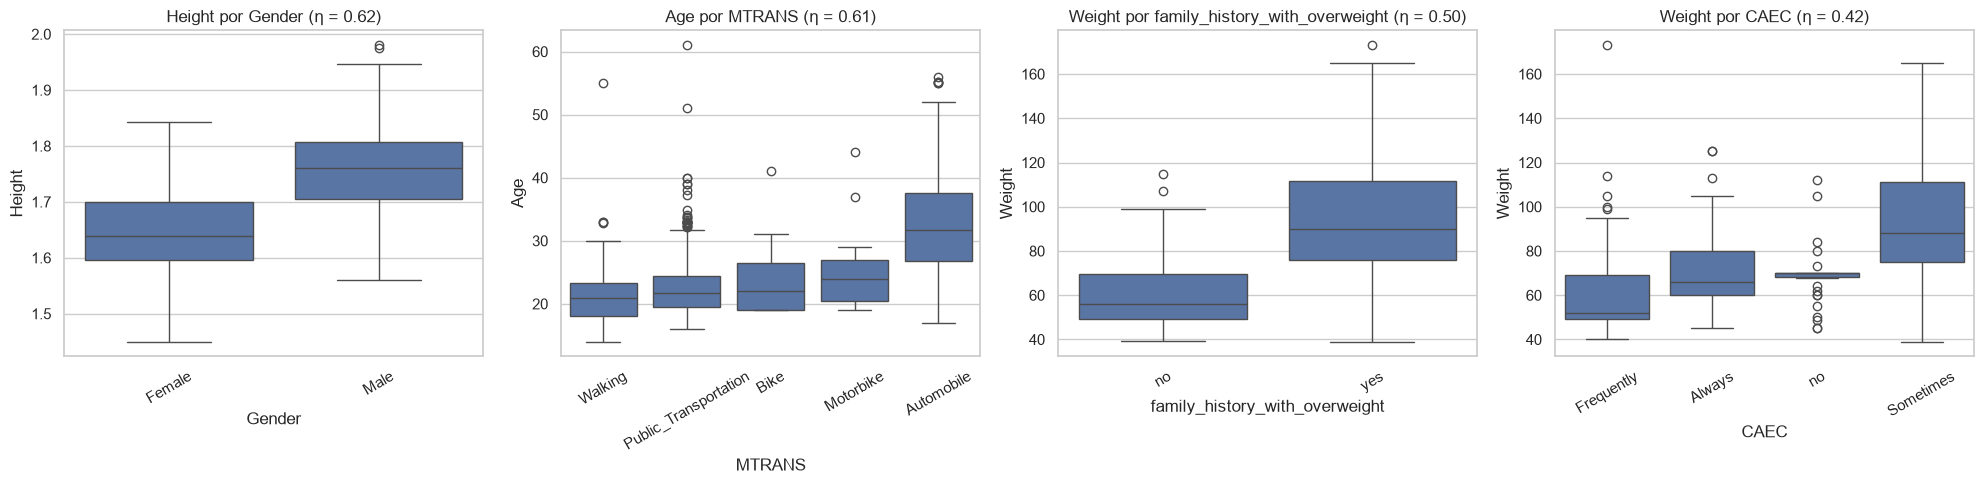

In [22]:
N_PARES = 4

pares = (
    matriz_eta.drop(columns=COL_CLASSE)
    .stack()
    .sort_values(ascending=False)
    .head(N_PARES)
)
display(pares.round(3).rename('eta').to_frame())

fig, axes = plt.subplots(1, N_PARES, figsize=(5 * N_PARES, 5), squeeze=False)
for ax, ((num, cat), eta) in zip(axes.flat, pares.items()):
    ordem = df.groupby(cat)[num].median().sort_values().index
    sns.boxplot(data=df, x=cat, y=num, order=ordem, ax=ax)
    ax.set_title(f'{num} por {cat} (η = {eta:.2f})')
    ax.set_xlabel(cat)
    ax.set_ylabel(num)
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
salvar(fig, 'eda_pares_numerica_categorica')
plt.show()

**Análise do grupo:**

A maior correlação linear entre as numéricas é a de altura e peso, com Pearson de aproximadamente 0,46. A idade e o tempo de uso de dispositivos (`TUE`) têm correlação de cerca de −0,30. As relações descrevem tendências na base, sem permitir inferências causais.

As distribuições por classe mostram diferenças de peso com sobreposição. As medianas são 50 kg em peso insuficiente, 61 kg em peso normal e 90,7 kg em obesidade tipo I. A mediana de obesidade tipo II é maior que a de tipo III, 117,8 kg contra 112,0 kg. O peso isolado, portanto, não acompanha toda a ordem das classes. O gráfico de altura e peso ajuda a contextualizar esse resultado.

As tabelas de proporções e o V de Cramér mostram associações entre categóricas e com a classe. Por exemplo, entre os registros sem histórico familiar de sobrepeso, prevalecem peso insuficiente e peso normal. A matriz η e os boxplots complementaram a análise relacional. Entre os pares de variáveis explicativas, destacaram-se altura × gênero, com η de 0,618, idade × transporte, com 0,607, e peso × histórico familiar, com 0,497. Esses valores descrevem associações na amostra.

## 4. Outliers

### Regra de 1,5 × IQR

In [23]:
def resumo_iqr(dados, cols):
    linhas = []
    for col in cols:
        q1, q3 = dados[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        fora = (dados[col] < lim_inf) | (dados[col] > lim_sup)
        linhas.append({
            'variavel': col,
            'q1': q1,
            'q3': q3,
            'lim_inf': lim_inf,
            'lim_sup': lim_sup,
            'n_outliers': int(fora.sum()),
            'pct_outliers': fora.mean() * 100,
        })
    return pd.DataFrame(linhas).set_index('variavel').round(3)


tabela_iqr = resumo_iqr(df, COLS_NUMERICAS)
tabela_iqr

,q1,q3,lim_inf,lim_sup,n_outliers,pct_outliers
variavel,,,,,,
Age,19.947,26.000,10.868,35.079,168,7.958
Height,1.630,1.768,1.422,1.976,1,0.047
Weight,65.473,107.431,2.537,170.367,1,0.047
FCVC,2.000,3.000,0.500,4.500,0,0.000
NCP,2.659,3.000,2.147,3.512,579,27.428
CH2O,1.585,2.477,0.246,3.816,0,0.000
FAF,0.125,1.667,-2.189,3.980,0,0.000
TUE,0.000,1.000,-1.500,2.500,0,0.000


### Z-score (|z| > 3)

In [24]:
z = (df[COLS_NUMERICAS] - df[COLS_NUMERICAS].mean()) / df[COLS_NUMERICAS].std()
(z.abs() > 3).sum().to_frame('n_outliers_z')

,n_outliers_z
Age,24
Height,0
Weight,1
FCVC,0
NCP,0
CH2O,0
FAF,0
TUE,0


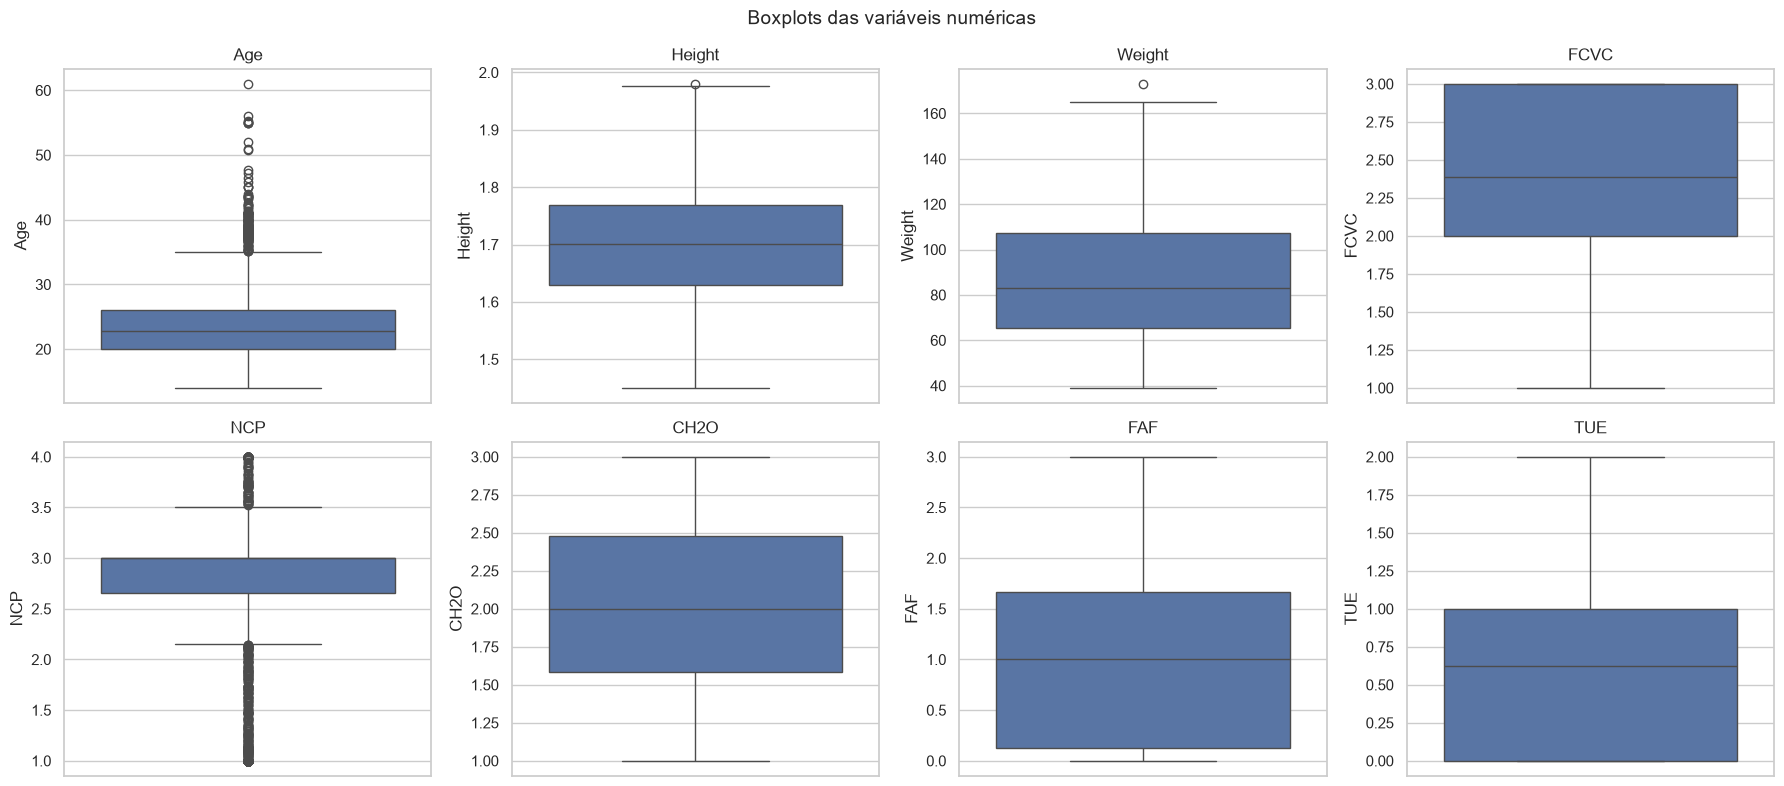

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, COLS_NUMERICAS):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel(col)
fig.suptitle('Boxplots das variáveis numéricas', fontsize=14)
fig.tight_layout()
salvar(fig, 'eda_boxplots')
plt.show()

### Em quais classes estão os outliers

In [26]:
fora_iqr = pd.DataFrame({
    col: (df[col] < tabela_iqr.loc[col, 'lim_inf']) | (df[col] > tabela_iqr.loc[col, 'lim_sup'])
    for col in COLS_NUMERICAS
})
cols_com_outlier = fora_iqr.columns[fora_iqr.any()].tolist()

outliers_por_classe = pd.concat(
    {c: df.loc[fora_iqr[c], COL_CLASSE].value_counts() for c in cols_com_outlier}, axis=1
)
outliers_por_classe.reindex(ORDEM_CLASSES).fillna(0).astype(int)

,Age,Height,Weight,NCP
NObeyesdad,,,,
Insufficient_Weight,1,0,0,124
Normal_Weight,7,0,0,81
Overweight_Level_I,22,0,0,122
Overweight_Level_II,39,0,0,89
Obesity_Type_I,70,1,0,110
Obesity_Type_II,29,0,0,53
Obesity_Type_III,0,0,1,0


In [27]:
df[fora_iqr.any(axis=1)]

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
4,Male,22.000000,1.780000,89.800000,no,no,2.000000,1.000000,Sometimes,no,2.000000,no,0.000000,0.000000,Sometimes,Public_Transportation,Overweight_Level_II
13,Male,41.000000,1.800000,99.000000,no,yes,2.000000,3.000000,Sometimes,no,2.000000,no,2.000000,1.000000,Frequently,Automobile,Obesity_Type_I
14,Male,23.000000,1.770000,60.000000,yes,yes,3.000000,1.000000,Sometimes,no,1.000000,no,1.000000,1.000000,Sometimes,Public_Transportation,Normal_Weight
16,Male,27.000000,1.930000,102.000000,yes,yes,2.000000,1.000000,Sometimes,no,1.000000,no,1.000000,0.000000,Sometimes,Public_Transportation,Overweight_Level_II
17,Female,29.000000,1.530000,78.000000,no,yes,2.000000,1.000000,Sometimes,no,2.000000,no,0.000000,0.000000,no,Automobile,Obesity_Type_I
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1794,Male,30.642430,1.653876,102.583895,yes,yes,2.919526,2.142328,Sometimes,no,1.175714,no,0.958555,0.636289,no,Public_Transportation,Obesity_Type_II
1795,Male,20.068432,1.657132,105.580491,yes,yes,2.724121,1.437959,Sometimes,no,1.590418,no,0.029603,1.122118,no,Public_Transportation,Obesity_Type_II
1796,Male,20.914366,1.644751,101.067988,yes,yes,2.801992,1.343117,Sometimes,no,1.128942,no,0.233987,0.819980,no,Public_Transportation,Obesity_Type_II
1797,Male,25.512048,1.660761,104.321463,yes,yes,2.748971,1.213431,Sometimes,no,1.448875,no,0.128548,1.239038,no,Public_Transportation,Obesity_Type_II


### Tratamento

**Outliers.** O critério de 1,5 × IQR sinalizou 168 valores de idade, um de altura, um de peso e 579 de `NCP`. O critério de z-score absoluto superior a 3 sinalizou 24 idades e um peso. Em `NCP`, a concentração em torno de três refeições estreita o intervalo interquartil. Por isso, a regra sinaliza valores plausíveis e remover os registros marcados nessa variável reduziria a base em 27,4%.

Os valores sinalizados foram mantidos porque a exploração não identificou evidência de erro que justificasse a exclusão. Pesos altos também podem ser informativos para o tema estudado. Como o K-Means minimiza distâncias quadráticas, valores extremos podem deslocar os centroides. O efeito de excluí-los não foi medido nas duas passadas.

**Duplicatas.** As 24 repetições, 1,14% da base, foram mantidas para preservar os dados fornecidos. Sem identificador individual, respostas iguais podem corresponder a participantes distintos. As repetições se concentram em sobrepeso nível I (14), peso insuficiente (5) e peso normal (5). Linhas repetidas atribuem mais peso aos respectivos perfis na formação dos grupos. Uma comparação com a base deduplicada seria necessária para medir esse efeito.

## 5. Síntese do grupo

Os rótulos têm frequências relativamente equilibradas, enquanto várias categorias explicativas são raras. As características físicas ajudam a diferenciar algumas classes, mas suas distribuições se sobrepõem. A combinação de escalas diferentes, atributos categóricos e dados sintéticos faz com que a interpretação dos clusters dependa das escolhas de representação e ponderação.